In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
tf.keras.utils.set_random_seed(42)

In [2]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [3]:
X_train = train.drop('label', axis=1)
y_train = train['label']

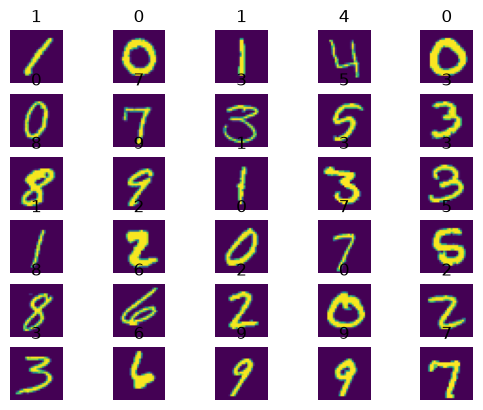

In [4]:
plt.figsize = (10, 10)
for i in range(30) :
    plt.subplot(6, 5, i+1)
    # plt.imshow(X_train = train.drop('label', axis=1)
    plt.imshow(X_train.iloc[i].values.reshape(28, 28), cmap='gray')
    plt.imshow(X_train.iloc[i].values.reshape(28, 28))
    # plt.imshow(X_train.iloc[i].values.reshape(28, 28), cmap=plt.cm.binary)
    plt.title(y_train.iloc[i])
    plt.axis('off')

In [5]:
X_train = X_train.values.reshape(-1, 28, 28, 1)
x_train = X_train / 255.0
y_train = tf.keras.utils.to_categorical(y_train, num_classes=10)

In [6]:
y_train

array([[0., 1., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.]], shape=(42000, 10))

In [7]:
model = models.Sequential()
model.add(layers.Conv2D(64, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(32, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(16, (3, 3), activation='relu'))
model.add(layers.Flatten())
model.add(layers.Dense(10, activation='softmax'))


c:\Users\besha\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [9]:
model.fit(X_train, y_train, epochs=10, validation_split=0.2, batch_size=128)

Epoch 1/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.7850 - loss: 0.7347 - val_accuracy: 0.9494 - val_loss: 0.1665
Epoch 2/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9588 - loss: 0.1363 - val_accuracy: 0.9667 - val_loss: 0.1086
Epoch 3/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9735 - loss: 0.0872 - val_accuracy: 0.9720 - val_loss: 0.0923
Epoch 4/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9796 - loss: 0.0650 - val_accuracy: 0.9774 - val_loss: 0.0779
Epoch 5/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9840 - loss: 0.0517 - val_accuracy: 0.9752 - val_loss: 0.0835
Epoch 6/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9860 - loss: 0.0442 - val_accuracy: 0.9776 - val_loss: 0.0853
Epoch 7/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9878 - loss: 0.0383 - val_accuracy: 0.9794 - val_loss: 0.0789
Epoch 8/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9890 - loss: 0.0338 - val_accu

In [10]:
x_test = test.values.reshape(-1, 28, 28, 1)
x_test = x_test / 255.0
y_pred = model.predict(x_test)

875/875 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step


In [11]:
y_pred

array([[0.09829179, 0.10383072, 0.10593957, ..., 0.10614205, 0.0949538 ,
        0.11234094],
       [0.10756683, 0.09780283, 0.09883332, ..., 0.10533196, 0.09380744,
        0.11613677],
       [0.09808059, 0.10516668, 0.09620789, ..., 0.10508247, 0.09556574,
        0.11919418],
       ...,
       [0.0995468 , 0.10394138, 0.09796441, ..., 0.10371258, 0.09575603,
        0.11615353],
       [0.09753693, 0.10691484, 0.09633097, ..., 0.10846741, 0.09222481,
        0.1183313 ],
       [0.0970922 , 0.10428027, 0.1054974 , ..., 0.10709033, 0.0945813 ,
        0.11225125]], shape=(28000, 10), dtype=float32)

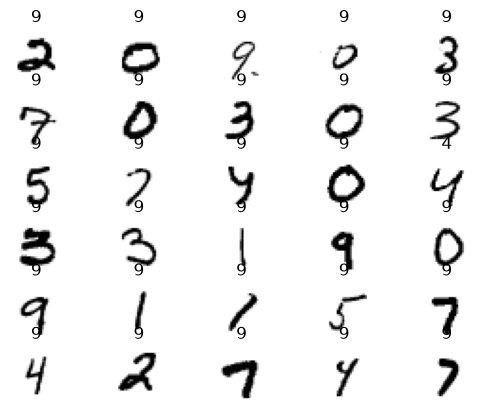

In [12]:
plt.figsize = (10, 10)
for i in range(30) :
    plt.subplot(6, 5, i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap=plt.cm.binary)
    plt.title(np.argmax(y_pred[i]))
    plt.axis('off')

In [13]:
submission = pd.DataFrame({'ImageId': list(range(1, len(y_pred) + 1)), 'Label': np.argmax(y_pred, axis=1)})
submission.to_csv('submission.csv', index=False)